# LoRA Fine-tuning: 고양이 12품종 이미지 분류

작성자: jeongin82 · 9주차 과제

원본 [skeleton.ipynb](https://github.com/HateSlop/5-week9/blob/main/skeleton.ipynb)의 24개 셀과 제공된 분할·Accuracy·평가·비교표·LoRA 적용·학습·저장 호출을 유지하고 TODO를 완성했습니다. 마지막에 실제 결과 요약 셀 1개를 추가했습니다.

Google Colab의 Tesla T4에서 학습·평가·저장·재로딩 검증을 실행했고 출력을 보존했습니다. 재현하려면 **런타임 → 런타임 유형 변경 → T4 GPU**를 선택하고 위에서부터 실행합니다. 실제 설치 버전과 모델·데이터 revision은 환경 셀에 기록했습니다.


## 1. 과제 설정

모델·데이터셋 이름과 선택 이유를 작성합니다. 예시는 영화 리뷰 감성 분석, 이미지 분류, 음성 명령 분류입니다.

In [6]:
TASK = "Vision"
MODEL_ID = "WinKawaks/vit-tiny-patch16-224"
DATASET_ID = "timm/oxford-iiit-pet"
SEED = 42
OUTPUT_DIR = "./assignment_runs"
EPOCHS = 5
BATCH_SIZE = 16
LEARNING_RATE = 5e-4

선택 이유: 고양이 사진을 보고 품종을 구별하는 문제에 관심이 있어 Oxford-IIIT Pet의 고양이 12품종을 선택했습니다. 데이터셋에는 공식 Train/Test와 종·품종 라벨이 있어 개 사진을 제외할 수 있습니다. 약 572만 파라미터의 ViT-Tiny는 무료 Colab의 메모리와 마감 시간을 고려한 선택입니다. 대형 생성 모델이나 Prompt 없이 이미지 분류를 수행합니다.

- 모델: https://huggingface.co/WinKawaks/vit-tiny-patch16-224 (Apache-2.0)
- 데이터: https://huggingface.co/datasets/timm/oxford-iiit-pet (해당 배포본의 표기: CC-BY-SA-4.0)
- 원 출처: Parkhi et al., *Cats and Dogs*, CVPR 2012, https://www.robots.ox.ac.uk/~vgg/data/pets/
- 구현 참고: https://huggingface.co/docs/peft/task_guides/image_classification_lora

특정 12품종 사이의 외형 분류이며, 혈통 확인이나 미등록 품종·믹스묘 판별 기능은 없습니다.

## 2. 실행 환경

아래 설치 코드는 공통 라이브러리를 설치하는 기본 예시입니다. 먼저 설치 셀과 import 셀을 실행하여 정상 작동하는지 확인합니다. 버전 충돌이 발생하면 오류 메시지와 공식 문서를 참고하여 설치할 버전을 조정합니다.


In [7]:
%pip install -q "transformers==4.57.1" "peft==0.17.1" "datasets==4.2.0" "accelerate==1.10.1" "huggingface_hub>=0.34,<1.0" pandas matplotlib scikit-learn pillow

In [8]:
import importlib.metadata
import os, time, hashlib, io, json, platform
from pathlib import Path
os.environ["TOKENIZERS_PARALLELISM"] = "false"
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from datasets import load_dataset, Dataset, DatasetDict, ClassLabel, Features, Array3D
from transformers import pipeline, set_seed, AutoImageProcessor, AutoModelForImageClassification
from peft import LoraConfig, get_peft_model, PeftModel
from huggingface_hub import HfApi
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

set_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("GPU가 없습니다. Colab 런타임 유형을 GPU로 변경하고 다시 실행하세요.")
print("Python:", platform.python_version())
print("GPU:", torch.cuda.get_device_name(0))
print("GPU memory GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))
versions = {p: importlib.metadata.version(p) for p in
            ("torch", "transformers", "datasets", "peft", "accelerate", "huggingface_hub", "pillow")}
display(pd.Series(versions, name="installed_version"))
MODEL_REVISION = HfApi().model_info(MODEL_ID).sha
DATASET_REVISION = HfApi().dataset_info(DATASET_ID).sha
print("Model revision:", MODEL_REVISION)
print("Dataset revision:", DATASET_REVISION)
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

Python: 3.13.16
GPU: Tesla T4
GPU memory GiB: 14.56


,installed_version
torch,2.14.1+cu130
transformers,4.57.1
datasets,4.2.0
peft,0.17.1
accelerate,1.10.1
huggingface_hub,0.36.2
pillow,11.3.0


Model revision: 77d1485af66b34d4ed0fe95dbb0c60c7496f950b
Dataset revision: 089695c834a7deb60505b7cc506672db1c31a6aa


## 3. 데이터 로딩과 분할

load_dataset으로 데이터를 불러와 Dataset 또는 DatasetDict를 반환합니다. 분할 이름이 다르면 train / validation / test로 맞춥니다. 제공된 함수가 기존 분할을 유지하고 없는 분할만 생성합니다. 분할이 없으면 80% / 10% / 10%로 나눕니다.

분할 결과의 크기와 클래스 분포를 확인합니다. 같은 화자·원본을 묶어야 하는 데이터에는 무작위 분할 대신 그룹별 분할을 적용합니다.


In [9]:
from datasets import Dataset, DatasetDict

def prepare_splits(data, seed=SEED):
    splits = DatasetDict({"train": data}) if isinstance(data, Dataset) else DatasetDict(data)
    if "train" not in splits:
        raise ValueError("학습용 분할의 이름을 train으로 지정하세요.")
    if "test" not in splits:
        split = splits["train"].train_test_split(test_size=0.1, seed=seed)
        splits["train"], splits["test"] = split["train"], split["test"]
        validation_ratio = 1 / 9
    else:
        validation_ratio = 0.1
    if "validation" not in splits:
        split = splits["train"].train_test_split(test_size=validation_ratio, seed=seed)
        splits["train"], splits["validation"] = split["train"], split["test"]
    return DatasetDict({name: splits[name] for name in ("train", "validation", "test")})

def load_data():
    """반환: Dataset 또는 train을 포함한 DatasetDict."""
    data = load_dataset(DATASET_ID, revision=DATASET_REVISION)
    breed_names = data["train"].features["label"].names
    species_names = data["train"].features["label_cat_dog"].names
    cat_id = species_names.index("cat")
    cats = DatasetDict({name: split.filter(
        lambda row: row["label_cat_dog"] == cat_id,
        input_columns=None, desc=f"고양이만 선택: {name}")
        for name, split in data.items()})
    global CLASS_NAMES, ID2LABEL, LABEL2ID
    old_ids = sorted(set(cats["train"]["label"]))
    CLASS_NAMES = [breed_names[i] for i in old_ids]
    assert len(CLASS_NAMES) == 12, CLASS_NAMES
    old_to_new = {old: new for new, old in enumerate(old_ids)}
    ID2LABEL = dict(enumerate(CLASS_NAMES))
    LABEL2ID = {name: i for i, name in ID2LABEL.items()}
    cats = cats.map(lambda row: {"label": old_to_new[row["label"]]}, desc="품종 ID를 0~11로 변환")
    cats = cats.cast_column("label", ClassLabel(names=CLASS_NAMES))
    # 공식 Test는 그대로 보존. 품종별 비율을 유지해 Train에서만 Validation 생성.
    split = cats["train"].train_test_split(test_size=0.2, seed=SEED, stratify_by_column="label")
    return DatasetDict(train=split["train"], validation=split["test"], test=cats["test"])

raw = prepare_splits(load_data())
print(raw)
print({k: v for k, v in raw["train"][0].items() if k != "image"})
distribution = pd.DataFrame({name: pd.Series(split["label"]).value_counts().reindex(
    range(12), fill_value=0) for name, split in raw.items()})
distribution.index = CLASS_NAMES
display(distribution)
assert (distribution > 0).all().all()

# 이미지 ID와 결정적으로 리사이즈한 RGB 픽셀의 해시로 중복을 확인합니다.
image_ids = {name: set(split["image_id"]) for name, split in raw.items()}
assert all(len(image_ids[n]) == len(raw[n]) for n in raw)
def image_digest(image):
    return hashlib.sha256(image.convert("RGB").resize((224, 224)).tobytes()).hexdigest()
digests = {name: {image_digest(row["image"]) for row in split} for name, split in raw.items()}
for left, right in (("train", "validation"), ("train", "test"), ("validation", "test")):
    assert not image_ids[left] & image_ids[right], f"이미지 ID 중복: {left}/{right}"
    assert not digests[left] & digests[right], f"이미지 내용 중복: {left}/{right}"
print("분할 간 이미지 ID 및 동일 리사이즈 픽셀 중복 없음")
print("주의: 개체 ID가 없어 동일 고양이 개체나 유사 사진의 완전 분리는 보장할 수 없습니다.")
TEST_IDS = tuple(raw["test"]["image_id"])
print("Test order SHA256:", hashlib.sha256("\n".join(TEST_IDS).encode()).hexdigest())

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id', 'label_cat_dog'],
        num_rows: 950
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id', 'label_cat_dog'],
        num_rows: 238
    })
    test: Dataset({
        features: ['image', 'label', 'image_id', 'label_cat_dog'],
        num_rows: 1183
    })
})
{'label': 4, 'image_id': 'British_Shorthair_125', 'label_cat_dog': 0}


,train,validation,test
abyssinian,80,20,98
bengal,80,20,100
birman,80,20,100
bombay,77,19,88
british_shorthair,80,20,100
egyptian_mau,74,19,97
maine_coon,80,20,100
persian,80,20,100
ragdoll,80,20,100
russian_blue,80,20,100


분할 간 이미지 ID 및 동일 리사이즈 픽셀 중복 없음
주의: 개체 ID가 없어 동일 고양이 개체나 유사 사진의 완전 분리는 보장할 수 없습니다.
Test order SHA256: 976862d04d15e76091fbe3be91c921ccb339e24b85250c3b22ca91108ec22edb


## 4. 모델과 전처리

Tokenizer / Image processor / Audio feature extractor 등을 선택합니다. 새 Classification head를 쓰면 초기화 사실과 레이블 매핑을 기록합니다. map으로 모델 입력과 labels를 구성합니다.

- Language: 텍스트·레이블 처리. 생성형 방식은 Prompt와 정답 구간의 Loss 처리를 결정합니다.
- Vision: 이미지 크기·정규화 처리
- Speech: Sampling rate·길이 처리

추론에서도 같은 전처리 의미를 유지합니다. Test 데이터에 학습용 무작위 증강을 적용하지 않습니다.

In [11]:
def load_model_and_processor():
    """반환: 사전학습 모델과 ImageProcessor."""
    processor = AutoImageProcessor.from_pretrained(MODEL_ID, revision=MODEL_REVISION, use_fast=False)
    model = AutoModelForImageClassification.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, num_labels=12,
        id2label=ID2LABEL, label2id=LABEL2ID, ignore_mismatched_sizes=True,
        attn_implementation="eager", use_safetensors=True)
    print("ImageNet 사전학습 backbone 사용, 12클래스 classifier는 새로 초기화")
    return model.cuda(), processor
set_seed(SEED)
model, processor = load_model_and_processor()
def preprocess(example):
    """반환: 모델 입력과 labels를 포함한 dict."""
    values = processor(images=example["image"].convert("RGB"), return_tensors="np")["pixel_values"][0]
    return {"pixel_values": values.astype(np.float32), "labels": int(example["label"])}
features = Features({"pixel_values": Array3D(shape=(3, 224, 224), dtype="float32"),
                     "labels": ClassLabel(names=CLASS_NAMES)})
prepared = raw.map(preprocess, remove_columns=raw["train"].column_names,
                   features=features, writer_batch_size=16, desc="결정적 이미지 전처리")
# 최신 torchvision에서 제거된 VideoReader를 참조하는 datasets torch formatter를 피합니다.
# 기본 Python 형식으로 읽고 collator에서 명시적으로 torch tensor로 변환합니다.
prepared.reset_format()
sample = {k: torch.as_tensor(v) for k, v in prepared["train"][0].items()}
print("pixel_values:", sample["pixel_values"].shape, sample["pixel_values"].dtype,
      "label:", sample["labels"].item())
assert sample["pixel_values"].shape == (3, 224, 224)
with torch.inference_mode():
    smoke = model(pixel_values=sample["pixel_values"].unsqueeze(0).cuda(),
                  labels=sample["labels"].reshape(1).cuda())
assert torch.isfinite(smoke.loss) and smoke.logits.shape == (1, 12)
print("1개 샘플 forward/loss 검증:", smoke.loss.item())

Fast image processor class <class 'transformers.models.vit.image_processing_vit_fast.ViTImageProcessorFast'> is available for this model. Using slow image processor class. To use the fast image processor class set `use_fast=True`.
Some weights of ViTForImageClassification were not initialized from the model checkpoint at WinKawaks/vit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([12]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([12, 192]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


ImageNet 사전학습 backbone 사용, 12클래스 classifier는 새로 초기화
pixel_values: torch.Size([3, 224, 224]) torch.float32 label: 4
1개 샘플 forward/loss 검증: 2.68341064453125


전처리·레이블 매핑·Classification head 초기화 여부:

이미지를 RGB로 변환한 뒤 모델의 ImageProcessor로 224×224 크기와 정규화를 일관되게 적용합니다. 학습·평가 모두 무작위 증강 없이 같은 전처리를 사용합니다. 고양이의 원래 37클래스 ID는 12클래스의 연속 ID 0~11로 다시 매핑합니다. ImageNet 1,000클래스 분류 헤드는 새 12클래스 헤드로 초기화합니다. 따라서 학습 전 평가는 무작위 초기화한 헤드를 포함한 기준선이며, 학습 전후 차이는 LoRA와 분류 헤드 학습의 결합 효과입니다.

## 5. 학습 전 평가

pipeline 추론 결과를 정답과 같은 형식의 레이블 목록으로 변환합니다. 예: 정답이 0/1이라면 예측도 0/1로 변환합니다. 생성형 모델이 유효하지 않은 답을 출력하면 정답과 일치하지 않는 레이블로 처리하고 평가에서 제외하지 않습니다.

아래 구현한 두 함수로 예측하면 Accuracy와 결과 표는 제공된 코드에서 자동 계산됩니다. Test 전체에서 평가하며, 정답을 추론 입력에 포함하지 않습니다. 학습 후에도 같은 데이터 순서·전처리·추론 설정을 사용합니다. 분류 외 태스크는 지표를 변경합니다.


In [12]:
def get_targets(test_data):
    """반환: Test 순서대로 정답 레이블을 담은 list."""
    return [int(x) for x in test_data["label"]]

def predict_labels(current_model, processor, test_data):
    """반환: Test 순서대로 예측 레이블을 담은 list."""
    current_model.eval()
    # PEFT 내부의 실제 ViT를 전달합니다. 주입된 LoRA와 학습된 classifier는 그대로 활성화됩니다.
    inference_model = current_model.get_base_model() if isinstance(current_model, PeftModel) else current_model
    pipe = pipeline("image-classification", model=inference_model, image_processor=processor, device=0)
    def images():
        for row in test_data:
            yield row["image"].convert("RGB")  # 정답과 품종이 들어간 파일명은 전달하지 않음
    predictions = []
    with torch.inference_mode():
        for result in pipe(images(), batch_size=BATCH_SIZE, top_k=1):
            predictions.append(LABEL2ID[result[0]["label"]])
    assert len(predictions) == len(test_data)
    return predictions

def accuracy(targets, predictions):
    if len(targets) == 0 or len(targets) != len(predictions):
        raise ValueError("정답과 예측은 길이가 같고 비어 있지 않아야 합니다.")
    return sum(a == b for a, b in zip(targets, predictions)) / len(targets)

def evaluate_model(current_model, processor, test_data):
    targets = get_targets(test_data)
    predictions = predict_labels(current_model, processor, test_data)
    if len(targets) != len(test_data):
        raise ValueError("Test의 모든 샘플에 대해 정답과 예측을 반환하세요.")
    metrics = {"accuracy": accuracy(targets, predictions)}
    table = pd.DataFrame({"sample_id": range(len(targets)), "target": targets,
                          "prediction": predictions})
    return metrics, table

baseline_started = time.perf_counter()
before_metrics, before = evaluate_model(model, processor, raw["test"])
print(before_metrics)
display(before.head())
print("학습 전 평가 시간(초):", round(time.perf_counter() - baseline_started, 1))

Device set to use cuda:0


{'accuracy': 0.06677937447168217}


,sample_id,target,prediction
0,0,7,1
1,1,11,2
2,2,0,11
3,3,4,1
4,4,11,6


학습 전 평가 시간(초): 10.9


## 6. LoRA 적용

모델의 모듈 이름을 확인한 뒤 target_modules, r, lora_alpha 등을 설정합니다. task_type은 해당 PEFT 지원 방식에 맞게 선택합니다. Classification head를 학습해야 한다면 modules_to_save 등 적절한 방법으로 포함하고, 저장 대상도 확인합니다.

In [13]:
def make_lora_config(model):
    """반환: 선택한 모델에 맞는 LoraConfig."""
    targets = [name for name, module in model.named_modules()
               if isinstance(module, torch.nn.Linear) and name.endswith((".query", ".value"))]
    assert len(targets) == 2 * model.config.num_hidden_layers, targets
    print("실제 LoRA 대상:", *targets, sep="\n")
    return LoraConfig(r=8, lora_alpha=16, lora_dropout=0.1,
                      target_modules=["query", "value"], bias="none",
                      modules_to_save=["classifier"])

lora_config = make_lora_config(model)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()
trainable_names = [name for name, p in model.named_parameters() if p.requires_grad]
assert trainable_names and all("lora_" in name or "classifier.modules_to_save" in name
                               for name in trainable_names), trainable_names
assert any("classifier.modules_to_save" in name for name in trainable_names)
display(pd.DataFrame({"trainable_module": trainable_names}))
trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_count = sum(p.numel() for p in model.parameters())

실제 LoRA 대상:
vit.encoder.layer.0.attention.attention.query
vit.encoder.layer.0.attention.attention.value
vit.encoder.layer.1.attention.attention.query
vit.encoder.layer.1.attention.attention.value
vit.encoder.layer.2.attention.attention.query
vit.encoder.layer.2.attention.attention.value
vit.encoder.layer.3.attention.attention.query
vit.encoder.layer.3.attention.attention.value
vit.encoder.layer.4.attention.attention.query
vit.encoder.layer.4.attention.attention.value
vit.encoder.layer.5.attention.attention.query
vit.encoder.layer.5.attention.attention.value
vit.encoder.layer.6.attention.attention.query
vit.encoder.layer.6.attention.attention.value
vit.encoder.layer.7.attention.attention.query
vit.encoder.layer.7.attention.attention.value
vit.encoder.layer.8.attention.attention.query
vit.encoder.layer.8.attention.attention.value
vit.encoder.layer.9.attention.attention.query
vit.encoder.layer.9.attention.attention.value
vit.encoder.layer.10.attention.attention.query
vit.encoder.layer.10.

,trainable_module
0,base_model.model.vit.encoder.layer.0.attention...
1,base_model.model.vit.encoder.layer.0.attention...
2,base_model.model.vit.encoder.layer.0.attention...
3,base_model.model.vit.encoder.layer.0.attention...
4,base_model.model.vit.encoder.layer.1.attention...
5,base_model.model.vit.encoder.layer.1.attention...
6,base_model.model.vit.encoder.layer.1.attention...
7,base_model.model.vit.encoder.layer.1.attention...
8,base_model.model.vit.encoder.layer.2.attention...
9,base_model.model.vit.encoder.layer.2.attention...


LoRA 설정 이유 및 실제 학습 대상 모듈:

각 Transformer 층의 Attention query와 value Linear에 rank 8, alpha 16, dropout 0.1의 LoRA를 적용합니다. 비교적 작은 rank로 학습 파라미터와 GPU 부담을 줄입니다. 실제 모듈 경로와 학습 가능한 파라미터 수는 위 출력에서 확인합니다. 새로 초기화한 classifier는 `modules_to_save=["classifier"]`로 학습·저장에 포함합니다. Vision 모델이므로 텍스트 태스크용 PEFT `task_type`을 강제로 지정하지 않습니다. 나머지 backbone 파라미터는 동결합니다.

## 7. 학습

TrainingArguments, Data collator, Trainer를 구성합니다. Train은 학습에, Validation은 설정 선택에 사용합니다. Test는 전달하지 않습니다. Padding·labels 및 Loss가 태스크와 맞는지 확인합니다.

In [14]:
def make_trainer(model, processor, train_data, validation_data):
    """반환: train() 메서드를 가진 Trainer. OUTPUT_DIR을 저장 경로로 사용합니다."""
    from transformers import TrainingArguments, Trainer
    def collate(batch):
        return {"pixel_values": torch.stack([torch.as_tensor(x["pixel_values"]) for x in batch]),
                "labels": torch.tensor([int(x["labels"]) for x in batch], dtype=torch.long)}
    def metrics(output):
        logits = output.predictions[0] if isinstance(output.predictions, tuple) else output.predictions
        return {"accuracy": float((np.argmax(logits, axis=-1) == output.label_ids).mean())}
    args = TrainingArguments(
        output_dir=OUTPUT_DIR, num_train_epochs=EPOCHS,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
        learning_rate=LEARNING_RATE, weight_decay=0.01, warmup_ratio=0.1,
        eval_strategy="epoch", save_strategy="epoch", load_best_model_at_end=True,
        metric_for_best_model="accuracy", greater_is_better=True, save_total_limit=1,
        fp16=True, logging_steps=10, report_to="none", remove_unused_columns=False,
        label_names=["labels"], dataloader_num_workers=0, seed=SEED, data_seed=SEED)
    return Trainer(model=model, args=args, train_dataset=train_data,
                   eval_dataset=validation_data, data_collator=collate,
                   compute_metrics=metrics)
trainer = make_trainer(model, processor, prepared["train"], prepared["validation"])
training_started = time.perf_counter()
train_result = trainer.train()
training_seconds = time.perf_counter() - training_started
print("학습 시간(초):", round(training_seconds, 1))
print("Validation 기준 최적 checkpoint:", trainer.state.best_model_checkpoint)
display(pd.DataFrame(trainer.state.log_history))
print("학습 설정:", {"epochs": EPOCHS, "batch_size": BATCH_SIZE,
                      "learning_rate": LEARNING_RATE, "seed": SEED,
                      "fp16": True, "best_model_selection": "validation accuracy"})

Epoch,Training Loss,Validation Loss,Accuracy
1,0.867700,0.726286,0.768908
2,0.330900,0.332825,0.890756
3,0.242300,0.276182,0.899160
4,0.128700,0.228260,0.932773
5,0.074700,0.215580,0.932773


학습 시간(초): 235.7
Validation 기준 최적 checkpoint: ./assignment_runs/checkpoint-240


,loss,grad_norm,learning_rate,epoch,step,eval_loss,eval_accuracy,eval_runtime,eval_samples_per_second,eval_steps_per_second,train_runtime,train_samples_per_second,train_steps_per_second,total_flos,train_loss
0,2.7936,14.742640,0.000150,0.166667,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2.6525,12.913411,0.000317,0.333333,20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2.2718,13.072762,0.000483,0.500000,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1.6195,12.605863,0.000483,0.666667,40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1.1335,8.841440,0.000465,0.833333,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.8677,12.201474,0.000446,1.000000,60,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,1.000000,60,0.726286,0.768908,9.1606,25.981,1.637,NaN,NaN,NaN,NaN,NaN
7,0.5723,7.351569,0.000428,1.166667,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,0.4896,9.577185,0.000409,1.333333,80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.4248,4.392222,0.000391,1.500000,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


학습 설정: {'epochs': 5, 'batch_size': 16, 'learning_rate': 0.0005, 'seed': 42, 'fp16': True, 'best_model_selection': 'validation accuracy'}


## 8. 학습 후 평가

학습 전 평가와 동일한 함수·Test 데이터를 사용합니다. 성능 향상이 없거나 실패한 사례도 그대로 기록합니다.

Device set to use cuda:0


,before,after
accuracy,0.066779,0.854607


,sample_id,target,before,after,image_id,target_breed,before_breed,after_breed
0,0,7,1,7,Persian_98,persian,bengal,persian
1,1,11,2,11,Sphynx_59,sphynx,birman,sphynx
2,2,0,11,0,Abyssinian_57,abyssinian,sphynx,abyssinian
3,3,4,1,4,British_Shorthair_269,british_shorthair,bengal,british_shorthair
4,4,11,6,11,Sphynx_239,sphynx,maine_coon,sphynx
5,5,4,1,4,British_Shorthair_89,british_shorthair,bengal,british_shorthair
6,6,2,2,2,Birman_62,birman,birman,birman
7,7,8,8,8,Ragdoll_45,ragdoll,ragdoll,ragdoll
8,8,4,11,4,British_Shorthair_70,british_shorthair,sphynx,british_shorthair
9,9,10,1,2,Siamese_240,siamese,bengal,birman


개선 사례: 942 악화 사례: 10 학습 후 오답: 172


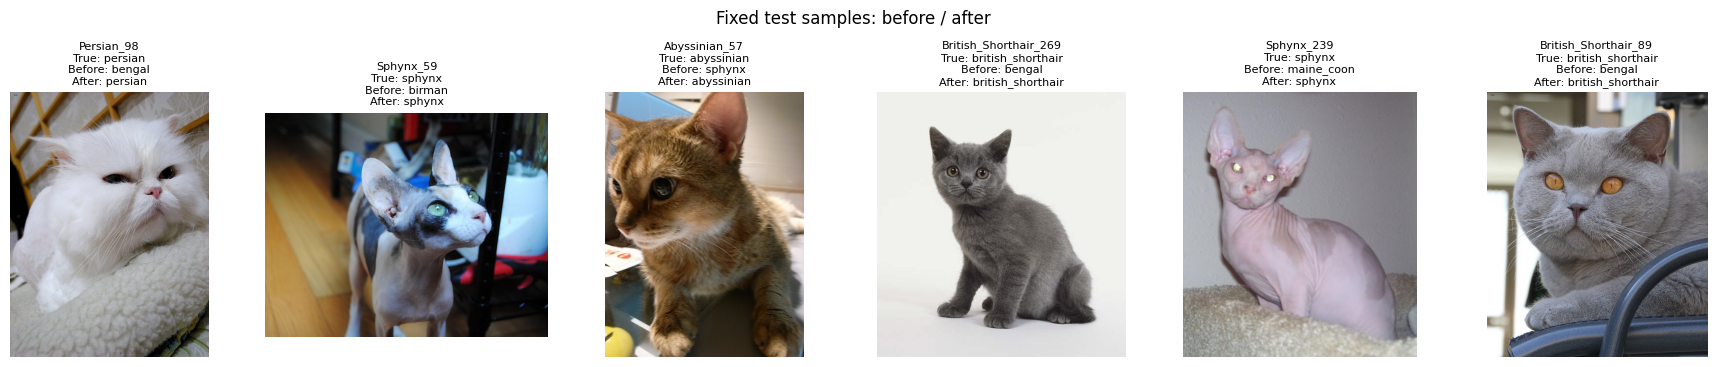

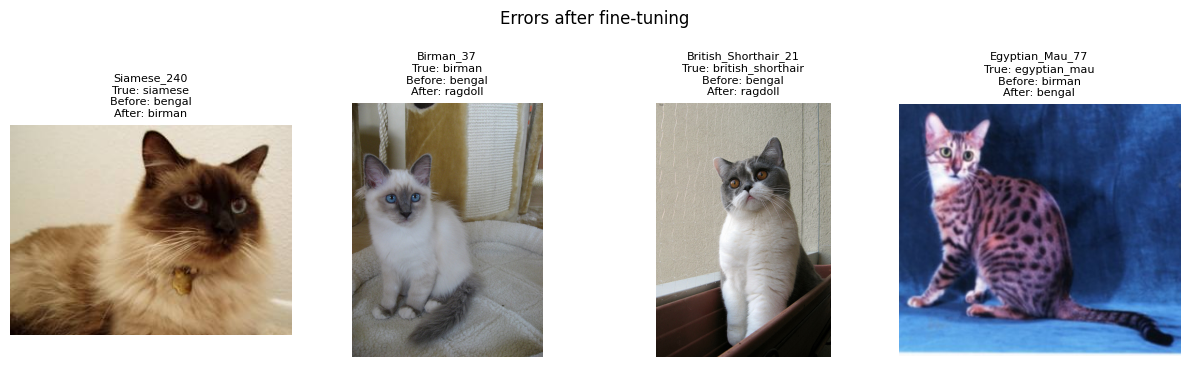

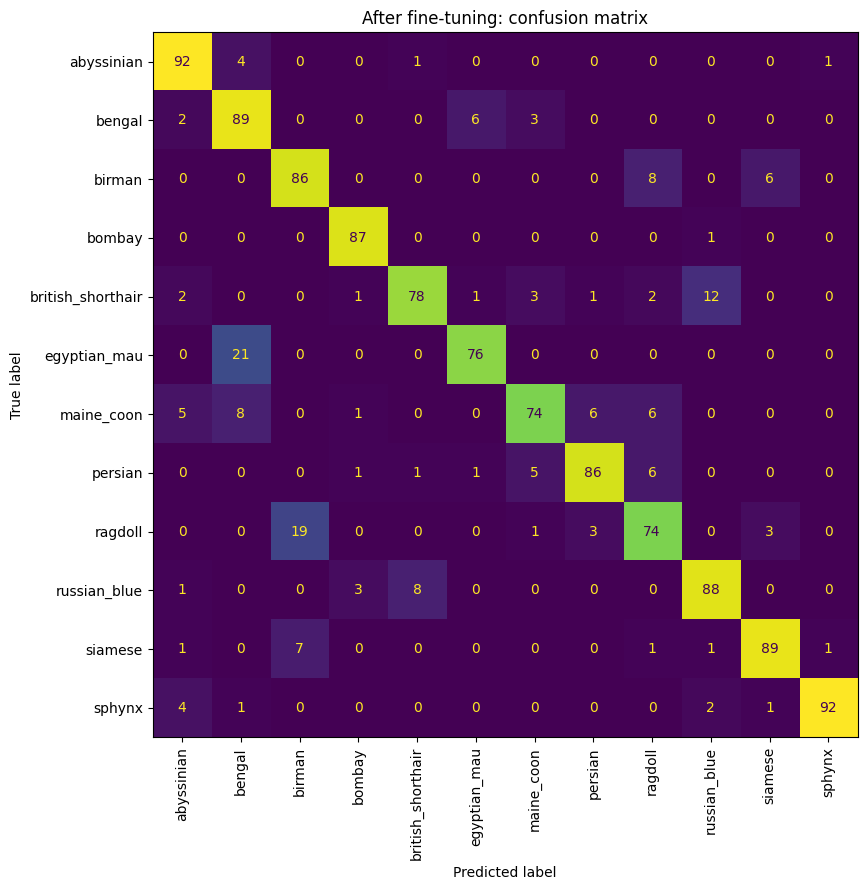

                   precision    recall  f1-score   support

       abyssinian       0.86      0.94      0.90        98
           bengal       0.72      0.89      0.80       100
           birman       0.77      0.86      0.81       100
           bombay       0.94      0.99      0.96        88
british_shorthair       0.89      0.78      0.83       100
     egyptian_mau       0.90      0.78      0.84        97
       maine_coon       0.86      0.74      0.80       100
          persian       0.90      0.86      0.88       100
          ragdoll       0.76      0.74      0.75       100
     russian_blue       0.85      0.88      0.86       100
          siamese       0.90      0.89      0.89       100
           sphynx       0.98      0.92      0.95       100

         accuracy                           0.85      1183
        macro avg       0.86      0.86      0.86      1183
     weighted avg       0.86      0.85      0.85      1183



In [15]:
assert tuple(raw["test"]["image_id"]) == TEST_IDS
after_metrics, after = evaluate_model(model, processor, raw["test"])
assert len(before) >= 5 and len(after) >= 5, "비교 샘플을 최소 5개 기록하세요."
assert before["sample_id"].is_unique and after["sample_id"].is_unique
assert before[["sample_id", "target"]].reset_index(drop=True).equals(
    after[["sample_id", "target"]].reset_index(drop=True)
), "학습 전후 동일한 샘플·순서·정답을 사용하세요."
comparison = before.rename(columns={"prediction": "before"}).merge(
    after[["sample_id", "prediction"]].rename(columns={"prediction": "after"}),
    on="sample_id", validate="one_to_one"
)
display(pd.DataFrame({"before": before_metrics, "after": after_metrics}))
comparison["image_id"] = TEST_IDS
for column in ("target", "before", "after"):
    comparison[column + "_breed"] = comparison[column].map(ID2LABEL)
display(comparison.head(12))
corrected = comparison[(comparison.before != comparison.target) & (comparison.after == comparison.target)]
regressed = comparison[(comparison.before == comparison.target) & (comparison.after != comparison.target)]
failed = comparison[comparison.after != comparison.target]
print("개선 사례:", len(corrected), "악화 사례:", len(regressed), "학습 후 오답:", len(failed))

# 대표 비교는 결과에 관계없이 사전 고정된 첫 6장으로 제시합니다.
def show_examples(indices, title):
    if not indices:
        print(title + ": 해당 사례 없음")
        return
    fig, axes = plt.subplots(1, len(indices), figsize=(3 * len(indices), 3.7), squeeze=False)
    for ax, index in zip(axes[0], indices):
        row = comparison.iloc[index]
        ax.imshow(raw["test"][index]["image"].convert("RGB"))
        ax.set_title(f"{row.image_id}\nTrue: {row.target_breed}\nBefore: {row.before_breed}\nAfter: {row.after_breed}", fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()
show_examples(list(range(6)), "Fixed test samples: before / after")
show_examples(failed.index[:4].tolist(), "Errors after fine-tuning")
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(comparison.target, comparison.after, labels=list(ID2LABEL),
    display_labels=CLASS_NAMES, xticks_rotation=90, ax=ax, colorbar=False)
plt.title("After fine-tuning: confusion matrix")
plt.tight_layout()
plt.show()
print(classification_report(comparison.target, comparison.after, labels=list(ID2LABEL),
                            target_names=CLASS_NAMES, zero_division=0))

## 9. 저장과 분석

Adapter를 저장합니다. 재사용에는 호환되는 Base model과 Processor·설정도 필요합니다. 추가 학습한 Classification head가 있다면 함께 저장되는지 확인합니다.

In [17]:
from pathlib import Path
adapter_dir = Path(OUTPUT_DIR) / "adapter"
model.save_pretrained(adapter_dir)
processor.save_pretrained(adapter_dir)
model.config.save_pretrained(adapter_dir)
# 저장 시 classifier와 LoRA가 포함됐는지 다시 로드하여 logits를 비교합니다.
from safetensors.torch import load_file
saved_keys = load_file(str(adapter_dir / "adapter_model.safetensors")).keys()
assert any("classifier" in key for key in saved_keys)
assert any("lora_A" in key for key in saved_keys)
reloaded_base = AutoModelForImageClassification.from_pretrained(
    MODEL_ID, revision=MODEL_REVISION, num_labels=12,
    id2label=ID2LABEL, label2id=LABEL2ID, ignore_mismatched_sizes=True,
    attn_implementation="eager", use_safetensors=True)
reloaded = PeftModel.from_pretrained(reloaded_base, adapter_dir).cuda().eval()
probe = torch.as_tensor(prepared["test"][0]["pixel_values"]).unsqueeze(0).cuda()
model.eval()
with torch.inference_mode():
    original_logits = model.get_base_model()(pixel_values=probe).logits
    restored_logits = reloaded.get_base_model()(pixel_values=probe).logits
print("동일한 FP32 추론 경로의 logits 최대 오차:", (original_logits - restored_logits).abs().max().item())
assert torch.allclose(original_logits, restored_logits, atol=1e-4, rtol=1e-4)
print("Adapter 재로딩 및 logits 일치 검증 통과")
del reloaded, reloaded_base
torch.cuda.empty_cache()
run_metadata = {"model_id": MODEL_ID, "model_revision": MODEL_REVISION,
                "dataset_id": DATASET_ID, "dataset_revision": DATASET_REVISION,
                "versions": versions, "seed": SEED, "before": before_metrics,
                "after": after_metrics, "split_sizes": {n: len(d) for n, d in raw.items()},
                "test_image_ids": list(TEST_IDS), "classes": CLASS_NAMES}
(adapter_dir / "run_metadata.json").write_text(json.dumps(run_metadata, ensure_ascii=False, indent=2))
print("Base model:", MODEL_ID, "Revision:", MODEL_REVISION)
print("Adapter·Processor·모델 설정 저장 위치:", adapter_dir.resolve())

Some weights of ViTForImageClassification were not initialized from the model checkpoint at WinKawaks/vit-tiny-patch16-224 and are newly initialized because the shapes did not match:
- classifier.bias: found shape torch.Size([1000]) in the checkpoint and torch.Size([12]) in the model instantiated
- classifier.weight: found shape torch.Size([1000, 192]) in the checkpoint and torch.Size([12, 192]) in the model instantiated
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


동일한 FP32 추론 경로의 logits 최대 오차: 0.0
Adapter 재로딩 및 logits 일치 검증 통과
Base model: WinKawaks/vit-tiny-patch16-224 Revision: 77d1485af66b34d4ed0fe95dbb0c60c7496f950b
Adapter·Processor·모델 설정 저장 위치: /content/assignment_runs/adapter


### 결과 분석

고정된 Test 1,183장에서 Accuracy가 **6.68% → 85.46%**로 **78.78%p** 상승했습니다. 학습 전 오답에서 학습 후 정답으로 바뀐 사진은 942장이고, 반대로 악화된 사진도 10장 있었습니다. 학습 후 오답 172장도 제외하지 않았습니다. 결과와 관계없이 고정한 첫 6개 샘플을 전후 비교 그림으로 제시하고, 별도로 첫 4개 오답을 표시했습니다.

학습 파라미터는 **76,044 / 5,602,776 (1.36%)**이며, 5 epochs 학습에 약 3.9분이 걸렸습니다. Validation Accuracy로 선택된 최종 모델은 Validation에서 93.28%, Test에서 85.46%를 기록했습니다. 약 7.82%p 차이가 있어 Validation 성능이 새 사진에서도 그대로 유지된다고 볼 수 없습니다. 학습에 사용한 사진이 950장으로 적고 데이터의 자세·조명·배경 차이가 있어 일반화의 한계를 함께 고려해야 합니다.

가장 많은 혼동은 **Egyptian Mau → Bengal 21건**이었습니다. 오답 그림의 `Egyptian_Mau_77`은 몸의 반점 무늬가 두드러지고 모델은 Bengal로 예측했습니다. 털무늬처럼 두 품종에서 겹치는 외형 단서가 혼동에 기여했을 가능성이 있습니다. `Siamese_240`은 Birman으로, `Birman_37`과 `British_Shorthair_21`은 Ragdoll로 예측했습니다. 이 사진들은 귀·얼굴 색과 밝은 몸통처럼 일부 단서가 겹쳐 보이지만, 이 관찰만으로 모델이 어떤 부분에 의존했는지 확정할 수는 없습니다. 클래스별 지표에서는 Ragdoll과 Maine Coon의 recall이 각각 0.74로 낮아 어려운 품종에 대한 추가 표본과 오류 분석이 필요합니다.

**해석 시 주의:** 학습 전 12클래스 헤드는 새로 초기화했으므로, 전후 차이는 LoRA와 분류 헤드 학습의 결합 효과입니다. LoRA 단독 효과를 분리하려면 헤드만 학습한 대조군이 필요합니다. 공식 분할을 유지하고 ID·동일 리사이즈 픽셀 중복을 검사했지만, 개체 ID가 없어 동일 고양이나 유사 사진의 완전한 분리는 보장하지 않습니다. 사전학습 데이터와 평가 이미지의 중복도 검증하지 않았습니다. 이 모델은 등록한 12품종 중 하나를 선택하며 미등록 품종·믹스묘나 혈통을 판별하지 못합니다.

**실행 환경과 저장:** 최신 Colab의 torchvision에서 제거된 VideoReader를 datasets의 torch/NumPy formatter가 참조하는 오류가 있어, 기본 Python 형식으로 읽고 collator에서 명시적으로 PyTorch 텐서로 변환했습니다. Adapter 재로딩 비교는 Trainer의 혼합 정밀도 래퍼 영향을 피하도록 두 모델의 같은 FP32 추론 경로에서 수행했고 logits 최대 오차는 **0.0**이었습니다. 설치 셀은 Colab의 기존 gradio·diffusers·gcsfs와 충돌 경고를 냈지만, 이 노트북은 이 패키지들을 사용하지 않으며 필요한 라이브러리 import부터 학습·평가·저장 검증까지 완료했습니다.

개선 방향은 Train에만 적용하는 이미지 증강, Validation으로만 선택하는 학습률·rank·epoch 조정, 더 큰 backbone과 헤드만 학습하는 대조 실험입니다. Test 결과로 설정을 다시 선택하지 않았습니다.

Adapter·분류 헤드·Processor·설정과 실행 메타데이터는 `/content/assignment_runs/adapter`에 저장했습니다. Colab 저장 공간은 임시이므로 재사용하려면 별도 보관해야 합니다. 과제 제출물은 코드·실행 출력·설명·분석이 포함된 **이 .ipynb 파일 하나**입니다.


In [18]:
delta = after_metrics["accuracy"] - before_metrics["accuracy"]
cm = confusion_matrix(comparison.target, comparison.after, labels=list(ID2LABEL))
np.fill_diagonal(cm, 0)
if cm.max() > 0:
    actual, predicted = np.unravel_index(cm.argmax(), cm.shape)
    confusion_text = f"가장 많은 혼동은 {ID2LABEL[actual]} → {ID2LABEL[predicted]} ({cm[actual, predicted]}건)이다."
else:
    confusion_text = "학습 후 Test 오분류는 없다."
display(Markdown(f"""
### 실제 실행 결과 해석
- 모델: `{MODEL_ID}` / revision `{MODEL_REVISION}`
- 데이터: `{DATASET_ID}` / revision `{DATASET_REVISION}`
- 분할 수: { {n: len(d) for n, d in raw.items()} }, Seed={SEED}
- Test Accuracy: **{before_metrics['accuracy']:.2%} → {after_metrics['accuracy']:.2%}**
- 변화: **{delta * 100:+.2f}%p**. {'개선되었다.' if delta > 0 else '개선되지 않았다.'} 이는 LoRA와 새 분류 헤드 학습의 결합 결과이다.
- 학습 파라미터: {trainable_count:,} / {total_count:,} ({trainable_count / total_count:.2%})
- 학습: {EPOCHS} epochs, batch {BATCH_SIZE}, learning rate {LEARNING_RATE}, 약 {training_seconds / 60:.1f}분. Validation Accuracy로 최적 checkpoint 선택.
- 개선 {len(corrected)}건, 악화 {len(regressed)}건, 학습 후 오답 {len(failed)}건. {confusion_text}
- 저장 위치: `{adapter_dir.resolve()}`. Adapter·분류 헤드·Processor·설정·실행 메타데이터를 저장하고 재로딩 logits 일치를 확인했다.
- Colab 저장 공간은 임시이므로 재사용하려면 Adapter 폴더도 별도 보관해야 한다. 과제 제출물에는 이 노트북만 포함한다.
"""))



### 실제 실행 결과 해석
- 모델: `WinKawaks/vit-tiny-patch16-224` / revision `77d1485af66b34d4ed0fe95dbb0c60c7496f950b`
- 데이터: `timm/oxford-iiit-pet` / revision `089695c834a7deb60505b7cc506672db1c31a6aa`
- 분할 수: {'train': 950, 'validation': 238, 'test': 1183}, Seed=42
- Test Accuracy: **6.68% → 85.46%**
- 변화: **+78.78%p**. 개선되었다. 이는 LoRA와 새 분류 헤드 학습의 결합 결과이다.
- 학습 파라미터: 76,044 / 5,602,776 (1.36%)
- 학습: 5 epochs, batch 16, learning rate 0.0005, 약 3.9분. Validation Accuracy로 최적 checkpoint 선택.
- 개선 942건, 악화 10건, 학습 후 오답 172건. 가장 많은 혼동은 egyptian_mau → bengal (21건)이다.
- 저장 위치: `/content/assignment_runs/adapter`. Adapter·분류 헤드·Processor·설정·실행 메타데이터를 저장하고 재로딩 logits 일치를 확인했다.
- Colab 저장 공간은 임시이므로 재사용하려면 Adapter 폴더도 별도 보관해야 한다. 과제 제출물에는 이 노트북만 포함한다.
